# 02 — Baselines : Naive, Moyenne, DLinear, ARIMA

**Objectif** : poser un **plancher** solide que les Transformers devront battre.

On évalue sur **ETTh1** aux horizons **96** et **192**, en mode multivarié (`M` : 7 → 7).
Les résultats sont sauvegardés dans `results/metrics/baselines.csv`.

Modèles :
1. **Naive (persistence)** — reproduit le dernier point d'entrée
2. **Moyenne glissante** — moyenne des `k` derniers pas
3. **DLinear** — décomposition + 2 linéaires (Zeng 2023)
4. **ARIMA** — baseline statistique sur `OT` univarié

In [ ]:
import sys, os, warnings, logging
sys.path.append(os.path.abspath('..'))
warnings.filterwarnings('ignore')
logging.getLogger('statsmodels').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from src.data_loader import load_dataset
from src.evaluate import all_metrics, plot_prediction, plot_error_per_horizon
from src.utils import set_seed, get_device, EarlyStopping, count_parameters
from src.models.dlinear import DLinear

set_seed(2026)
device = get_device()
print('device:', device)

## Préparation des données

In [2]:
INPUT_LEN = 96
BATCH = 32
HORIZONS = [96, 192]

results = []       # liste de dicts pour construire un DataFrame final

## 1. Naive (persistence)

Pour chaque horizon `h`, on prédit `y_{t+h} = y_t` (le dernier pas d'entrée est répété).

In [3]:
def naive_predict(x, pred_len):
    # x : (B, L, C) -> on repete le dernier pas pred_len fois
    last = x[:, -1:, :]
    return last.repeat(1, pred_len, 1)

for h in HORIZONS:
    _, _, test, _ = load_dataset('ETTh1', input_len=INPUT_LEN, pred_len=h, batch_size=BATCH)
    preds, trues = [], []
    for x, y in test:
        preds.append(naive_predict(x, h).numpy())
        trues.append(y.numpy())
    p, t = np.concatenate(preds), np.concatenate(trues)
    m = all_metrics(p, t)
    results.append({'model': 'Naive', 'horizon': h, **m})
    print(f'Naive  h={h:3d}  MSE={m["MSE"]:.4f}  MAE={m["MAE"]:.4f}')

Naive  h= 96  MSE=1.2944  MAE=0.7132


Naive  h=192  MSE=1.3249  MAE=0.7331


## 2. Moyenne glissante (fenetre = 24 = 1 jour)

In [4]:
def moving_avg_predict(x, pred_len, k=24):
    avg = x[:, -k:, :].mean(dim=1, keepdim=True)
    return avg.repeat(1, pred_len, 1)

for h in HORIZONS:
    _, _, test, _ = load_dataset('ETTh1', input_len=INPUT_LEN, pred_len=h, batch_size=BATCH)
    preds, trues = [], []
    for x, y in test:
        preds.append(moving_avg_predict(x, h).numpy())
        trues.append(y.numpy())
    p, t = np.concatenate(preds), np.concatenate(trues)
    m = all_metrics(p, t)
    results.append({'model': 'MovingAvg', 'horizon': h, **m})
    print(f'MovAvg h={h:3d}  MSE={m["MSE"]:.4f}  MAE={m["MAE"]:.4f}')

MovAvg h= 96  MSE=0.7275  MAE=0.5700


MovAvg h=192  MSE=0.7484  MAE=0.5832


## 3. DLinear — entrainement + evaluation

On entraine DLinear separement pour chaque horizon, avec early stopping sur la val loss.

In [5]:
def train_dlinear(h, epochs=20, lr=1e-3, patience=5):
    train, val, test, _ = load_dataset('ETTh1', input_len=INPUT_LEN, pred_len=h, batch_size=BATCH)
    model = DLinear(input_len=INPUT_LEN, pred_len=h, n_channels=7, kernel_size=25, individual=True).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    es = EarlyStopping(patience=patience, path=f'../results/checkpoints/dlinear_h{h}.pt')

    for ep in range(epochs):
        model.train()
        tr_loss = 0.0
        for x, y in train:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tr_loss += loss.item() * x.size(0)
        tr_loss /= len(train.dataset)

        model.eval()
        with torch.no_grad():
            vl = sum(loss_fn(model(x.to(device)), y.to(device)).item() * x.size(0)
                     for x, y in val) / len(val.dataset)
        es(vl, model)
        print(f'  ep {ep+1:2d}  train={tr_loss:.4f}  val={vl:.4f}'  + ('  *best*' if es.counter == 0 else ''))
        if es.should_stop:
            print(f'  early stopping a l\'epoch {ep+1}')
            break

    model.load_state_dict(torch.load(es.path, weights_only=True))
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x, y in test:
            preds.append(model(x.to(device)).cpu().numpy())
            trues.append(y.numpy())
    return np.concatenate(preds), np.concatenate(trues), model

dlinear_preds = {}
for h in HORIZONS:
    print(f'\n=== DLinear h={h} ===')
    p, t, model = train_dlinear(h)
    m = all_metrics(p, t)
    results.append({'model': 'DLinear', 'horizon': h, **m})
    print(f'=> MSE={m["MSE"]:.4f}  MAE={m["MAE"]:.4f}  (params={count_parameters(model):,})')
    dlinear_preds[h] = (p, t)


=== DLinear h=96 ===


  ep  1  train=0.4128  val=0.6847  *best*


  ep  2  train=0.3490  val=0.6791  *best*


  ep  3  train=0.3452  val=0.6650  *best*


  ep  4  train=0.3428  val=0.6617  *best*


  ep  5  train=0.3409  val=0.6688


... (25 outputs left out)

  ep 14  train=0.3962  val=0.8961


  ep 15  train=0.3959  val=0.9147


  ep 16  train=0.3962  val=0.8990
  early stopping a l'epoch 16


=> MSE=0.4409  MAE=0.4268  (params=260,736)


## 4. ARIMA — baseline univariee sur OT

ARIMA est **couteux** (une fit par fenetre) : on l'evalue uniquement sur un sous-echantillon du test pour le temps.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)

def arima_eval(h, n_samples=100, order=(5, 0, 1)):
    _, _, test, scaler = load_dataset('ETTh1', input_len=INPUT_LEN, pred_len=h, batch_size=1)
    preds, trues = [], []
    for i, (x, y) in enumerate(test):
        if i >= n_samples:
            break
        serie = x[0, :, -1].numpy()        # colonne OT (derniere)
        try:
            fit = ARIMA(serie, order=order).fit()
            preds.append(fit.forecast(steps=h))
        except Exception:
            preds.append(np.full(h, serie[-1]))
        trues.append(y[0, :, -1].numpy())
    p = np.array(preds)
    t = np.array(trues)
    return all_metrics(p, t)

for h in HORIZONS:
    print(f'ARIMA h={h}  (sur 100 fenetres)...', end=' ', flush=True)
    m = arima_eval(h, n_samples=100)
    results.append({'model': 'ARIMA(5,0,1)_OT', 'horizon': h, **m})
    print(f'MSE={m["MSE"]:.4f}  MAE={m["MAE"]:.4f}')

## Tableau comparatif + sauvegarde

In [7]:
df_res = pd.DataFrame(results).round(4).sort_values(['horizon', 'MSE'])
df_res

,model,horizon,MSE,MAE,RMSE,MAPE,sMAPE
6,"ARIMA(5,0,1)_OT",96,0.0423,0.1590,0.2056,25.1535,22.2295
4,DLinear,96,0.3953,0.4058,0.6287,919.5148,74.4230
2,MovingAvg,96,0.7275,0.5700,0.8529,1311.7637,99.9282
0,Naive,96,1.2944,0.7132,1.1377,1663.2460,102.0743
7,"ARIMA(5,0,1)_OT",192,0.0484,0.1747,0.2199,25.2008,23.3229
5,DLinear,192,0.4409,0.4268,0.6640,894.3214,78.0765
3,MovingAvg,192,0.7484,0.5832,0.8651,1380.4529,101.7478
1,Naive,192,1.3249,0.7331,1.1510,1742.7961,104.1772


In [8]:
out = Path('../results/metrics/baselines.csv')
out.parent.mkdir(parents=True, exist_ok=True)
df_res.to_csv(out, index=False)
print(f'Sauvegarde : {out.resolve()}')

Sauvegarde : C:\Users\lenovo\projet7-transformers-ts\results\metrics\baselines.csv


## Visualisations : une prediction DLinear + erreur par horizon

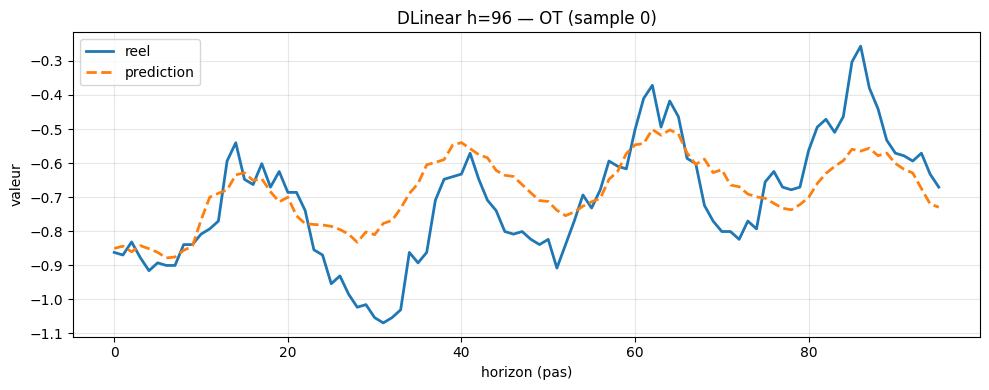

In [9]:
p, t = dlinear_preds[96]
plot_prediction(p, t, sample_idx=0, feature_idx=-1, title='DLinear h=96 — OT (sample 0)');

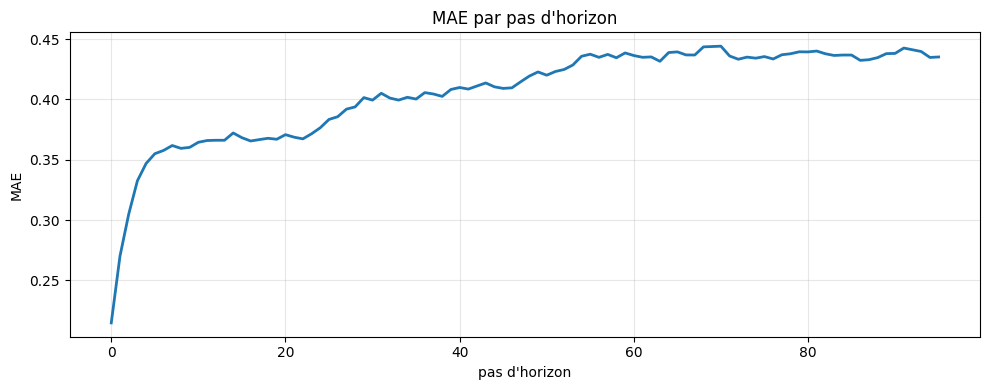

In [10]:
plot_error_per_horizon(p, t, metric='MAE');

## Conclusion

- **Naive** et **MovingAvg** sont volontairement simples : ils bornent par le bas.
- **DLinear** devrait être **significativement meilleur** — c'est le vrai plancher à battre.
- **ARIMA** sur OT univarié sert de référence statistique.

**Prochaine étape** : implémenter les Transformers (`src/models/`) et les comparer aux mêmes horizons sur `ETTh1`.